# Exercise 5.4.2: training a reconstruction network
In this exercise we will train two simple reconstruction networks for

- an image denoising problem and
- an image inpainting inverse problem

Follow these steps for each inverse problem:

1. Get a dataset of images. You can use the CBSD68 dataset for training and the set3c dataset for testing. Resize images to 128x128 pixels (larger images take longer to train, and for this exercise, we can work with smaller images). Split the training set into 60 training and 8 validation images.
2. Define the forward operator (identity plus noise for denoising problem or masking operator for inpainting problem).
3. Define the reconstruction architecture. Use a [U-Net](https://arxiv.org/pdf/1505.04597) (a common neural network architecture for imaging problems) $R_\theta$ with trainable parameters $\theta$. The reconstruction of a corrupted image $y$ is $\hat{x} = R_\theta(y)$. After training the network by optimizing its parameters $\theta$ we expect $\hat x \approx y$.
4. Train the reconstruction network on the training data. At each training epoch plot the PSNR of reconstructions and example images of source, measurements, and reconstruction.
5. Test the trained network on your testset and compare the PSNR before and after training on the testset.
6. Plot examples of reconstructed test images.



## Change runtime type and install DeepInverse package
First, we install the deepinverse library. Remeber to change the runtime of this notebook select ``Runtime`` -> ``Change runtime type`` and pick an available hardware accelerator.

In [ ]:
!pip install git+https://github.com/deepinv/deepinv.git#egg=deepinv

  Cloning https://github.com/deepinv/deepinv.git to /tmp/pip-install-e1lcznm5/deepinv_1bad9b5c52884c469583ec31b815fd6e
  Running command git clone --filter=blob:none --quiet https://github.com/deepinv/deepinv.git /tmp/pip-install-e1lcznm5/deepinv_1bad9b5c52884c469583ec31b815fd6e
  Resolved https://github.com/deepinv/deepinv.git to commit f304b6adc964e0054fd182d1044c7af11d2d116a
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 77.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 64.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 41.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00
   ━━

In [2]:
import deepinv as dinv
from torch.utils.data import DataLoader
import torch
from pathlib import Path
from torchvision import transforms
from deepinv.utils.demo import load_dataset

import matplotlib.pyplot as plt

# Setup paths for data loading and checkpoints

In [3]:
BASE_DIR = Path(".")
DATA_DIR = BASE_DIR / "measurements"
CKPT_DIR = BASE_DIR / "ckpts"

# Set the global random seed from pytorch to ensure reproducibility of the example.
torch.manual_seed(0)

device = dinv.utils.get_freer_gpu() if torch.cuda.is_available() else "cpu"

Selected GPU 0 with 5828.4375 MiB free memory


# Load base image datasets and degradation operators
In this example, we use the CBSD68 dataset for training and the set3c dataset for testing. We work with images of size 32x32 if no GPU is available, else 128x128.

To split CBSD68 into training and validation datasets
1. Use `torch.randperm` https://docs.pytorch.org/docs/stable/generated/torch.randperm.html to generate random permutation of indices.
2. Use `torch.utils.data.Subset` https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.Subset to select a subset of the dataset.

In [4]:
operation = "denoising"
train_dataset_name = "CBSD68"
test_dataset_name = "set3c"

img_size = 128 if torch.cuda.is_available() else 32

test_transform = transforms.Compose(
    [transforms.CenterCrop(img_size), transforms.ToTensor()]
)
train_transform = transforms.Compose(
    [transforms.RandomCrop(img_size), transforms.ToTensor()]
)

train_dataset = load_dataset(train_dataset_name, train_transform)
val_dataset = load_dataset(train_dataset_name, test_transform) 
test_dataset = load_dataset(test_dataset_name, test_transform)

# Select 8 validation images
indices = torch.randperm(len(train_dataset))
val_size = 8
train_dataset = torch.utils.data.Subset(train_dataset, indices[:-val_size])
val_dataset = torch.utils.data.Subset(val_dataset, indices[-val_size:])

# Plot an image from a dataset
Try plotting it multiple times! Why does it produce different images for the training set?
Read about data augmentation and transforms at https://docs.pytorch.org/vision/0.9/transforms.html and https://deepinv.github.io/deepinv/user_guide/training/transforms.html#transform.

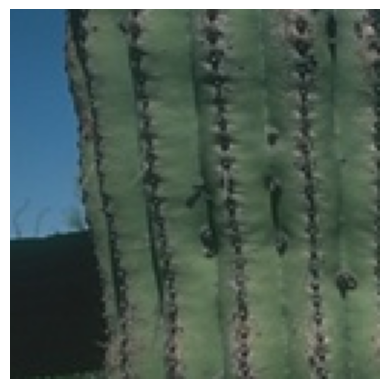

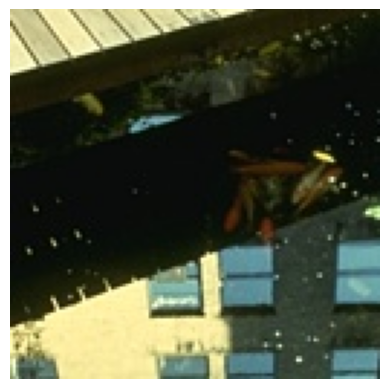

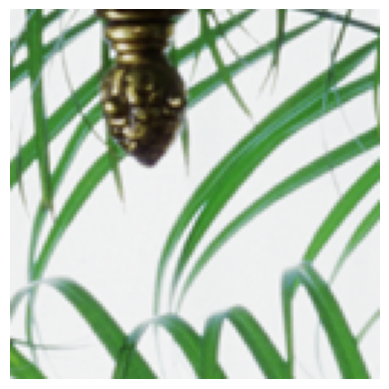

In [12]:
plt.imshow(train_dataset[0].permute(1, 2, 0))
plt.axis("off")
plt.show()

plt.imshow(val_dataset[0].permute(1, 2, 0))
plt.axis("off")
plt.show()

plt.imshow(test_dataset[0].permute(1, 2, 0))
plt.axis("off")
plt.show()

# Set up physics
Define a physics object corresponding to denoising problem with Gaussian noise and standard deviation $\sigma = 0.05$. See [this overview](https://deepinv.github.io/deepinv/auto_examples/physics/demo_physics_tour.html) and a [complete list](https://deepinv.github.io/deepinv/api/deepinv.physics.html) of physics models available at DeepInverse.

In [15]:
physics = dinv.physics.Denoising(dinv.physics.GaussianNoise(0.05))

# Prepare dataloaders
Dataloaders handle loading datasets into memory. You can set up the batchs size and whether you want the elements be randomly reschuffled, see Remark 5.3.4.

In [16]:
n_channels = 3 
num_workers = 4 if torch.cuda.is_available() else 1

train_batch_size = 16 if torch.cuda.is_available() else 1
val_batch_size = 16 if torch.cuda.is_available() else 1
test_batch_size = 16 if torch.cuda.is_available() else 1

train_dataloader = DataLoader(
    train_dataset, batch_size=train_batch_size, num_workers=num_workers, shuffle=True
)

val_dataloader = DataLoader(
    val_dataset, batch_size=val_batch_size, num_workers=num_workers, shuffle=False
)

test_dataloader = DataLoader(
    test_dataset, batch_size=test_batch_size, num_workers=num_workers, shuffle=False
)

# Set up the reconstruction network

We use [U-Net](https://arxiv.org/pdf/1505.04597) for colored images, both as input and output. Morevore, to reduce the number of parameters, three scales (downsampling layers) would be sufficient.

See https://deepinv.github.io/deepinv/api/stubs/deepinv.models.UNet.html for more details.

In [17]:
model = dinv.models.UNet(
    in_channels=3, out_channels=3, scales=3, batch_norm=False
).to(device)

print(model)

UNet(
  (Maxpool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (Conv1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (Conv2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (Conv3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (Up3): Sequential(
    (0): Upsample(scale_factor=2.0, mode='nearest')
    (1): Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): ReLU(inplace=True)
  )
  (Up_conv3): Seque

# Set up a Trainer
Trainer is a ready-made class for training a network. It takes model, physics, dataloaders, and training parameters as input and trains the network accordingly. Try different numbers of epochs and learning rates to see which works best. Note: Given the limited free GPU access on Colab, going beyond 300 epochs is not recommended. 

See https://deepinv.github.io/deepinv/user_guide/training/trainer.html#trainer
and https://deepinv.github.io/deepinv/api/stubs/deepinv.Trainer.html for more details.

In [18]:
verbose = True  # print training information
wandb_vis = False  # plot curves and images in Weight&Bias

epochs = 200  # choose training epochs
learning_rate = 5e-4

# choose training losses
losses = dinv.loss.SupLoss(metric=dinv.metric.MSE())

# choose optimizer and scheduler
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-8)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=epochs)
trainer = dinv.Trainer(
    model,
    device=device,
    save_path=str(CKPT_DIR / operation),
    verbose=verbose,
    wandb_vis=wandb_vis,
    physics=physics,
    epochs=epochs,
    scheduler=scheduler,
    losses=losses,
    optimizer=optimizer,
    show_progress_bar=False,  # disable progress bar for better vis in sphinx gallery.
    train_dataloader=train_dataloader,
    eval_dataloader=val_dataloader,
    plot_images=False, # You can plot images, to see the network's actual denoising. Significantly increases the size of the notebook.
    plot_measurements=True,
    online_measurements=True,  # Do our datasets contain both (x_i, y_i) or we want to generate y_i = physics(x_i) on the fly?
    no_learning_method = "y", # Baseline to compare with: options 'y', 'A_dagger', 'A_adjoint', 'prox_l2'
    ckp_interval = 5, # Store network parameters every ckp_interval epochs. Very useful in practice.
)

In [6]:
trainer.train()

The model has 2067779 trainable parameters
Train epoch 0: TotalLoss=0.003, PSNR=25.767
Eval epoch 0: PSNR=25.999
Best model saved at epoch 1
Train epoch 1: TotalLoss=0.003, PSNR=25.996
Eval epoch 1: PSNR=26.037
Best model saved at epoch 2
Train epoch 2: TotalLoss=0.002, PSNR=26.031
Eval epoch 2: PSNR=26.061
Best model saved at epoch 3
Train epoch 3: TotalLoss=0.002, PSNR=26.065
Eval epoch 3: PSNR=26.087
Best model saved at epoch 4
Train epoch 4: TotalLoss=0.002, PSNR=26.104
Eval epoch 4: PSNR=26.126
Best model saved at epoch 5
Train epoch 5: TotalLoss=0.002, PSNR=26.153
Eval epoch 5: PSNR=26.193
Best model saved at epoch 6
Train epoch 6: TotalLoss=0.002, PSNR=26.236
Eval epoch 6: PSNR=26.307
Best model saved at epoch 7
Train epoch 7: TotalLoss=0.002, PSNR=26.345
Eval epoch 7: PSNR=26.436
Best model saved at epoch 8
Train epoch 8: TotalLoss=0.002, PSNR=26.516
Eval epoch 8: PSNR=26.658
Best model saved at epoch 9
Train epoch 9: TotalLoss=0.002, PSNR=26.758
Eval epoch 9: PSNR=26.936
Best 

Eval epoch 0: PSNR=32.2, PSNR no learning=26.018


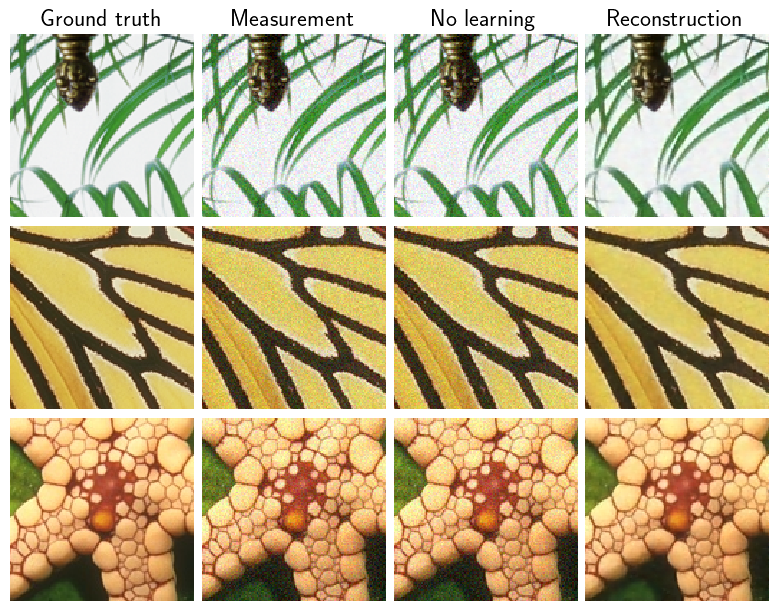

Test results:
PSNR no learning: 26.018 +- 0.015
PSNR: 32.200 +- 1.295


{'PSNR no learning': 26.017972310384113,
 'PSNR no learning_std': 0.014701698529515172,
 'PSNR': 32.19957478841146,
 'PSNR_std': 1.2945375451928014}

In [19]:
# load model with best validation PSNR
model = trainer.load_best_model()
trainer.plot_images = True
trainer.test(test_dataloader)

# Plot an example of reconstruction

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.101668164..1.1774242].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.01058531..1.092805].


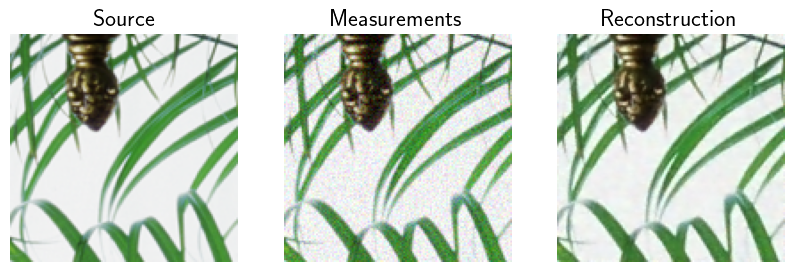

In [20]:
source = next(iter(test_dataloader))
measurement = physics(source)
y_hat = model(measurement.to(device), physics)

plt.subplots(1, 3, figsize=(10, 5))
plt.subplot(1, 3, 1)
plt.imshow(source[0].permute(1, 2, 0))
plt.axis("off")
plt.title('Source')

plt.subplot(1, 3, 2)
plt.imshow(measurement[0].permute(1, 2, 0))
plt.axis("off")
plt.title('Measurements')

plt.subplot(1, 3, 3)
plt.imshow(y_hat[0].detach().cpu().permute(1, 2, 0))
plt.axis("off")
plt.title('Reconstruction')

plt.show()

# Impainting

Change the physics to the inpainting problem from Exercise 4.3.38. Set up a UNet model

In [22]:
operation = "inpainting"

probability_mask = 0.3

physics_im = dinv.physics.Inpainting(
    img_size=(n_channels, img_size, img_size), mask=probability_mask, device=device
)

model_im = dinv.models.UNet(
    in_channels=3, out_channels=3, scales=3, batch_norm=False
).to(device)

# Set up a Trainer and train a UNet for inpainting problem

In [26]:
verbose = True  # print training information
wandb_vis = False  # plot curves and images in Weight&Bias

epochs = 200  # choose training epochs
learning_rate = 5e-4

# choose training losses
losses = dinv.loss.SupLoss(metric=dinv.metric.MSE())

# choose optimizer and scheduler
optimizer = torch.optim.Adam(model_im.parameters(), lr=learning_rate, weight_decay=1e-8)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=epochs)
trainer_im = dinv.Trainer(
    model_im,
    device=device,
    save_path=str(CKPT_DIR / operation),
    verbose=verbose,
    wandb_vis=wandb_vis,
    physics=physics_im,
    epochs=epochs,
    scheduler=scheduler,
    losses=losses,
    optimizer=optimizer,
    show_progress_bar=False,  # disable progress bar for better vis in sphinx gallery.
    train_dataloader=train_dataloader,
    eval_dataloader=val_dataloader,
    plot_images=False,
    plot_measurements=True,
    online_measurements=True,
    # no_learning_method = "y",
    ckp_interval = 5,
)

In [ ]:
trainer_im.train()

Eval epoch 0: PSNR=22.958, PSNR no learning=5.202


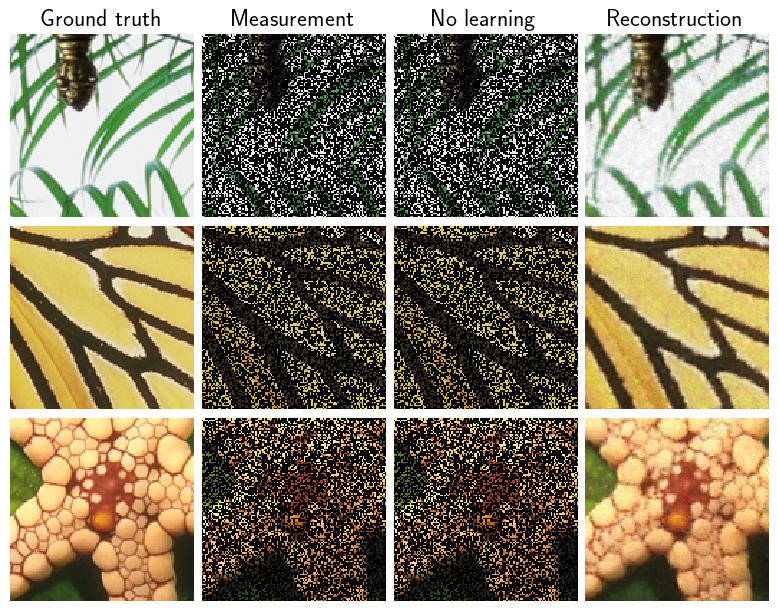

Test results:
PSNR no learning: 5.202 +- 0.911
PSNR: 22.958 +- 0.717


{'PSNR no learning': 5.201526006062825,
 'PSNR no learning_std': 0.9107050332756617,
 'PSNR': 22.957626342773438,
 'PSNR_std': 0.7169112330070925}

In [27]:
# load model with best validation PSNR
model_im = trainer_im.load_best_model()
trainer_im.plot_images = True
trainer_im.test(test_dataloader)

# Plot an example of reconstruction

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.00794944..1.0784491].


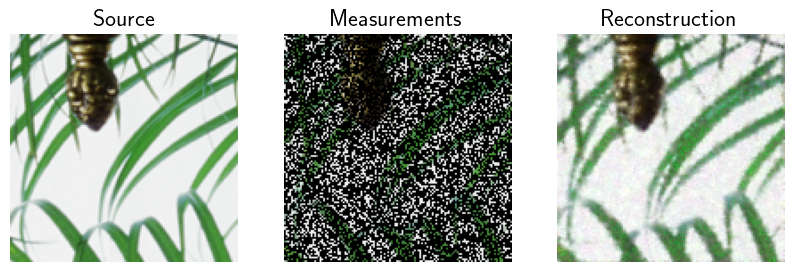

In [28]:
source = next(iter(test_dataloader))
measurement = physics_im(source.to(device))
y_hat = model_im(measurement.to(device), physics)

plt.subplots(1, 3, figsize=(10, 5))
plt.subplot(1, 3, 1)
plt.imshow(source[0].permute(1, 2, 0).cpu())
plt.axis("off")
plt.title('Source')

plt.subplot(1, 3, 2)
plt.imshow(measurement[0].permute(1, 2, 0).cpu())
plt.axis("off")
plt.title('Measurements')

plt.subplot(1, 3, 3)
plt.imshow(y_hat[0].detach().cpu().permute(1, 2, 0))
plt.axis("off")
plt.title('Reconstruction')

plt.show()